
# Analisi delle vendite e segmentazione clienti — Online Retail

## Obiettivo del progetto

Questo progetto analizza un dataset di transazioni e-commerce per comprendere l'andamento delle vendite e il comportamento dei clienti.

L'analisi è stata realizzata con Python, Pandas e Matplotlib e comprende:

- Esplorazione e pulizia dei dati
- Calcolo dei principali KPI di vendita
- Analisi dei ricavi per Paese
- Analisi dei prodotti più redditizi
- Analisi dell'andamento mensile delle vendite
- Segmentazione dei clienti con il modello RFM

**Dataset:** Online Retail — UCI Machine Learning Repository.

**Nota metodologica:** l'analisi dei ricavi considera le transazioni di vendita positive, escludendo cancellazioni e valori non validi. Non rappresenta quindi il fatturato netto dei resi.


In [4]:
# Importazione delle librerie

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Definizione della cartella in cui salvare i grafici
cartella = r"C:\Users\MSI\Desktop\Progetti\analisi-clienti\images"

# Creazione della cartella, se non esiste già§
os.makedirs(cartella, exist_ok=True)

## 1. Caricamento e prima esplorazione dei dati

In questa sezione carichiamo il dataset Online Retail e analizziamo la sua struttura iniziale.

In [5]:
# Caricamento del dataset Online Retail

percorso_file = r"C:\Users\MSI\Desktop\Progetti\analisi-clienti\Online Retail.xlsx"

df = pd.read_excel(percorso_file)

# Visualizzazione delle prime cinque righe
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 1.1 Esplorazione iniziale

Esaminiamo le dimensioni del dataset, le colonne disponibili, i tipi di dato e le statistiche descrittive.

In [6]:
# Dimensioni del dataset
print("Dimensioni del dataset:", df.shape)

# Informazioni sulle colonne e sui valori mancanti
df.info()

# Statistiche descrittive delle variabili numeriche
display(df.describe())

# Conteggio dei valori mancanti per colonna
print("\nValori mancanti:")
display(df.isnull().sum())

Dimensioni del dataset: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



Valori mancanti:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 2. Pulizia dei dati

### 2.1 Individuazione e rimozione dei duplicati

Verifichiamo la presenza di righe duplicate e le rimuoviamo per evitare che le stesse transazioni vengano conteggiate più volte.

In [7]:
# Creazione di una copia del dataset originale
df_originale = df.copy()

# Conteggio delle righe duplicate
duplicati = df.duplicated().sum()

print("Numero di righe duplicate:", duplicati)

# Rimozione dei duplicati
df = df.drop_duplicates().copy()

# Verifica delle nuove dimensioni
print("Dimensioni dopo la rimozione:", df.shape)

Numero di righe duplicate: 5268
Dimensioni dopo la rimozione: (536641, 8)


### 2.2 Analisi delle anomalie

Analizziamo le transazioni per individuare cancellazioni, quantità negative e prezzi unitari nulli o negativi.

Questi controlli ci permettono di comprendere la qualità dei dati prima di creare il dataset destinato all'analisi delle vendite.

In [8]:
# Individuazione delle fatture annullate
fatture_annullate = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Fatture annullate:", len(fatture_annullate))

# Quantità negative
quantita_negative = df[df["Quantity"] < 0]

print("Righe con quantità negative:", len(quantita_negative))

# Quantità negative non associate a fatture annullate
quantita_negative_non_annullate = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]

print(
    "Quantità negative senza fattura annullata:",
    len(quantita_negative_non_annullate)
)

# Prezzi unitari pari a zero o negativi
prezzi_zero = df[df["UnitPrice"] == 0]
prezzi_negativi = df[df["UnitPrice"] < 0]

print("Prezzi unitari pari a zero:", len(prezzi_zero))
print("Prezzi unitari negativi:", len(prezzi_negativi))

# Quantità pari a zero
quantita_zero = df[df["Quantity"] == 0]

print("Righe con quantità pari a zero:", len(quantita_zero))

Fatture annullate: 9251
Righe con quantità negative: 10587
Quantità negative senza fattura annullata: 1336
Prezzi unitari pari a zero: 2510
Prezzi unitari negativi: 2
Righe con quantità pari a zero: 0


### 2.3 Creazione del dataset delle vendite

Creiamo un dataset dedicato all'analisi delle vendite positive.

Escludiamo:
- Le fatture annullate.
- Le righe con quantità pari o inferiori a zero.
- Le righe con prezzo unitario pari o inferiore a zero.

Calcoliamo inoltre il ricavo di ogni riga moltiplicando quantità e prezzo unitario.

Il dataset ottenuto sarà utilizzato per le successive analisi commerciali.

In [9]:
# Creazione del dataset contenente solo le vendite positive

df_pulito = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calcolo del ricavo per ogni riga
df_pulito["Revenue"] = (
    df_pulito["Quantity"] * df_pulito["UnitPrice"]
)

# Verifica delle dimensioni del dataset pulito
print("Dimensioni dataset originale:", df.shape)
print("Dimensioni dataset pulito:", df_pulito.shape)

# Visualizzazione delle prime righe
display(df_pulito.head())

Dimensioni dataset originale: (536641, 8)
Dimensioni dataset pulito: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [10]:
# Controllo dei valori mancanti dopo la pulizia

print("Valori mancanti nel dataset pulito:")
display(df_pulito.isnull().sum())

Valori mancanti nel dataset pulito:


InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

## 3. Analisi dei principali KPI

Calcoliamo i principali indicatori di performance delle vendite per ottenere una panoramica generale dell'attività commerciale.

Gli indicatori considerati sono:
- Ricavi totali
- Numero di ordini
- Numero di prodotti distinti
- Numero di clienti identificati
- Quantità totale venduta
- Ricavo medio per riga
- Valore medio degli ordini (Average Order Value)

In [11]:
# Calcolo dei principali KPI di vendita

ricavi_totali = df_pulito["Revenue"].sum()
numero_ordini = df_pulito["InvoiceNo"].nunique()
numero_prodotti = df_pulito["StockCode"].nunique()
numero_clienti = df_pulito["CustomerID"].nunique()
quantita_venduta = df_pulito["Quantity"].sum()
ricavo_medio_riga = df_pulito["Revenue"].mean()

# Calcolo del valore medio degli ordini
ricavi_per_ordine = df_pulito.groupby("InvoiceNo")["Revenue"].sum()
valore_medio_ordine = ricavi_per_ordine.mean()

# Funzione per formattare gli importi in formato italiano
def formato_euro(valore):
    return f"{valore:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".") + " €"

# Visualizzazione dei KPI
print(f"Ricavi totali: {formato_euro(ricavi_totali)}")
print(f"Numero di ordini: {numero_ordini:,}".replace(",", "."))
print(f"Prodotti distinti: {numero_prodotti:,}".replace(",", "."))
print(f"Clienti identificati: {numero_clienti:,}".replace(",", "."))
print(f"Quantità totale venduta: {quantita_venduta:,}".replace(",", "."))
print(f"Ricavo medio per riga: {formato_euro(ricavo_medio_riga)}")
print(f"Valore medio per ordine: {formato_euro(valore_medio_ordine)}")

Ricavi totali: 10.642.110,80 €
Numero di ordini: 19.960
Prodotti distinti: 3.922
Clienti identificati: 4.338
Quantità totale venduta: 5.572.420
Ricavo medio per riga: 20,28 €
Valore medio per ordine: 533,17 €


## 4. Analisi dei ricavi per Paese

Analizziamo la distribuzione geografica dei ricavi per individuare i mercati più importanti.

Calcoliamo i ricavi generati da ciascun Paese e selezioniamo i primi dieci per valore.

Top 10 Paesi per ricavi


,Paese,Ricavi
0,United Kingdom,"9.001.744,09 €"
1,Netherlands,"285.446,34 €"
2,EIRE,"283.140,52 €"
3,Germany,"228.678,40 €"
4,France,"209.625,37 €"
5,Australia,"138.453,81 €"
6,Spain,"61.558,56 €"
7,Switzerland,"57.067,60 €"
8,Belgium,"41.196,34 €"
9,Sweden,"38.367,83 €"



Incidenza del Regno Unito sul totale: 84,59%


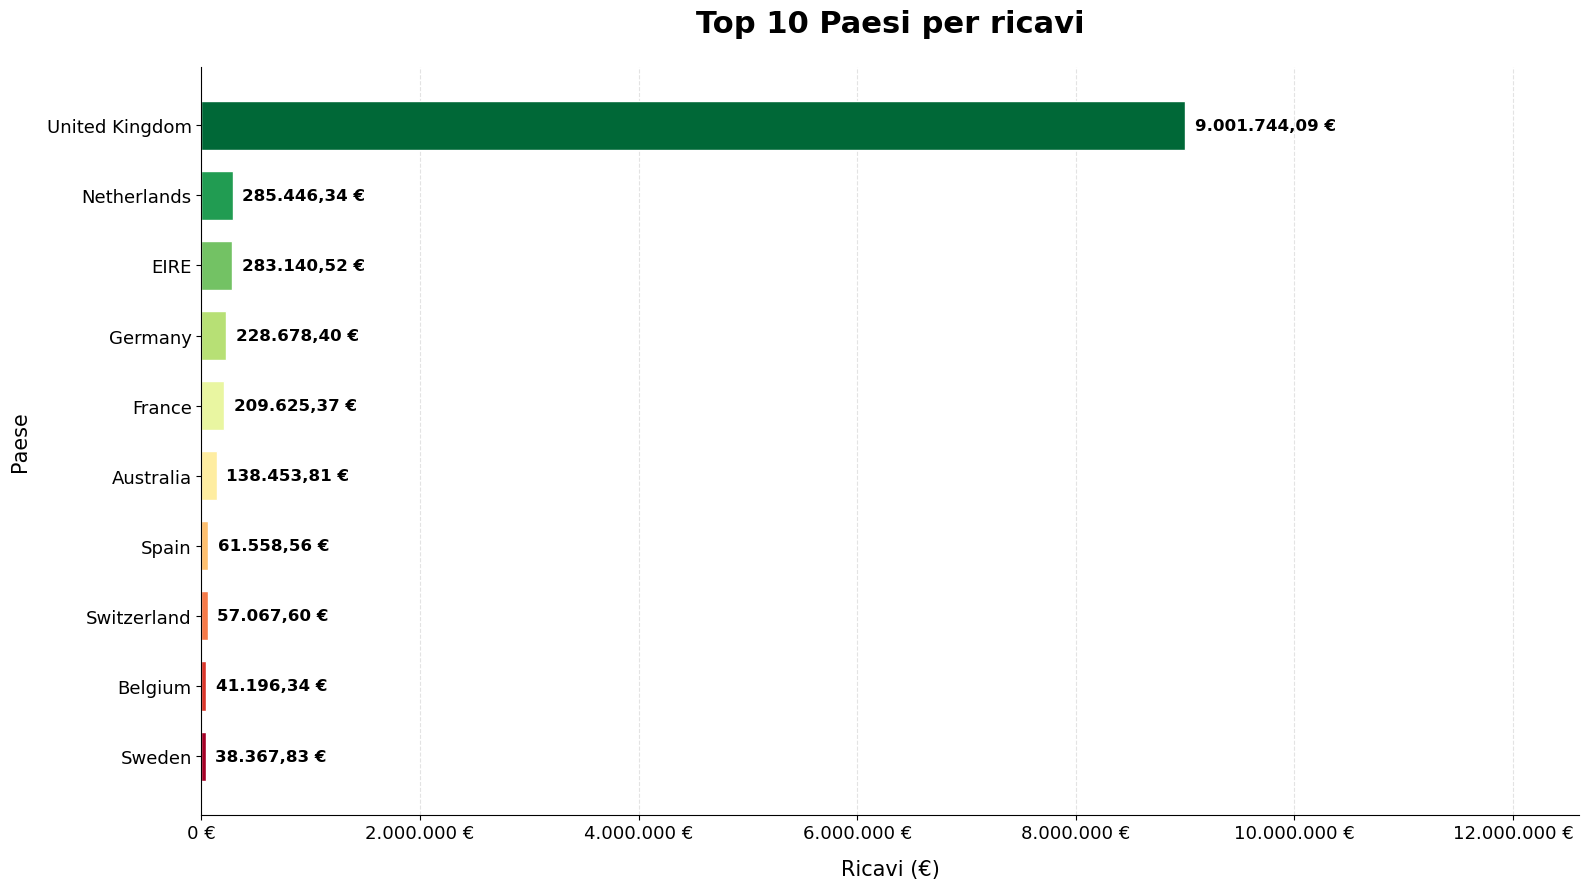

In [12]:
# Calcolo dei ricavi per Paese
ricavi_paese = (
    df_pulito.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Selezione dei primi 10 Paesi
top_10_paesi = ricavi_paese.head(10)

# Funzione per formattare gli importi in formato italiano
def formato_euro(valore):
    return (
        f"{valore:,.2f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
        + " €"
    )

# Creazione di una tabella con i ricavi dei primi 10 Paesi
tabella_paesi = pd.DataFrame({
    "Paese": top_10_paesi.index,
    "Ricavi": top_10_paesi.values
})

# Formattazione dei ricavi
tabella_paesi["Ricavi"] = tabella_paesi["Ricavi"].apply(formato_euro)

# Visualizzazione dei risultati
print("Top 10 Paesi per ricavi")
display(tabella_paesi)

# Calcolo della percentuale dei ricavi generati dal Regno Unito
percentuale_uk = (
    ricavi_paese["United Kingdom"] / ricavi_paese.sum()
) * 100

print(
    f"\nIncidenza del Regno Unito sul totale: "
    f"{percentuale_uk:.2f}%".replace(".", ",")
)

# Creazione del grafico
dati_grafico = top_10_paesi.sort_values()

fig, ax = plt.subplots(figsize=(16, 9))

# Creazione della palette dal rosso al verde
colori = plt.cm.RdYlGn(
    [i / (len(dati_grafico) - 1) for i in range(len(dati_grafico))]
)

# Creazione delle barre orizzontali
barre = ax.barh(
    dati_grafico.index,
    dati_grafico.values,
    color=colori,
    edgecolor="white",
    height=0.7
)

# Impostazione del titolo e delle etichette
ax.set_title(
    "Top 10 Paesi per ricavi",
    fontsize=22,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Ricavi (€)", fontsize=15, labelpad=12)
ax.set_ylabel("Paese", fontsize=15, labelpad=12)

# Aumento della dimensione delle etichette
ax.tick_params(axis="both", labelsize=13)

# Formattazione dell'asse dei ricavi
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".") + " €"
    )
)

# Aggiunta della griglia
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Visualizzazione dei valori accanto alle barre
for barra in barre:
    valore = barra.get_width()

    ax.text(
        valore + max(dati_grafico.values) * 0.01,
        barra.get_y() + barra.get_height() / 2,
        formato_euro(valore),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

# Impostazione dello spazio per le etichette
ax.set_xlim(0, max(dati_grafico.values) * 1.40)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    os.path.join(cartella, "ricavi_paese.png"),
    dpi=300,
    bbox_inches="tight"
)

# Visualizzazione del grafico
plt.show()

## 5. Analisi dei prodotti

Analizziamo i prodotti che generano i maggiori ricavi per individuare gli articoli più rilevanti dal punto di vista commerciale.

Calcoliamo il ricavo totale per prodotto e selezioniamo i primi dieci.

Top 10 prodotti per ricavi


,Prodotto,Ricavi
0,DOTCOM POSTAGE,"206.248,77 €"
1,REGENCY CAKESTAND 3 TIER,"174.156,54 €"
2,"PAPER CRAFT , LITTLE BIRDIE","168.469,60 €"
3,WHITE HANGING HEART T-LIGHT HOLDER,"106.236,72 €"
4,PARTY BUNTING,"99.445,23 €"
5,JUMBO BAG RED RETROSPOT,"94.159,81 €"
6,MEDIUM CERAMIC TOP STORAGE JAR,"81.700,92 €"
7,POSTAGE,"78.101,88 €"
8,Manual,"77.752,82 €"
9,RABBIT NIGHT LIGHT,"66.870,03 €"


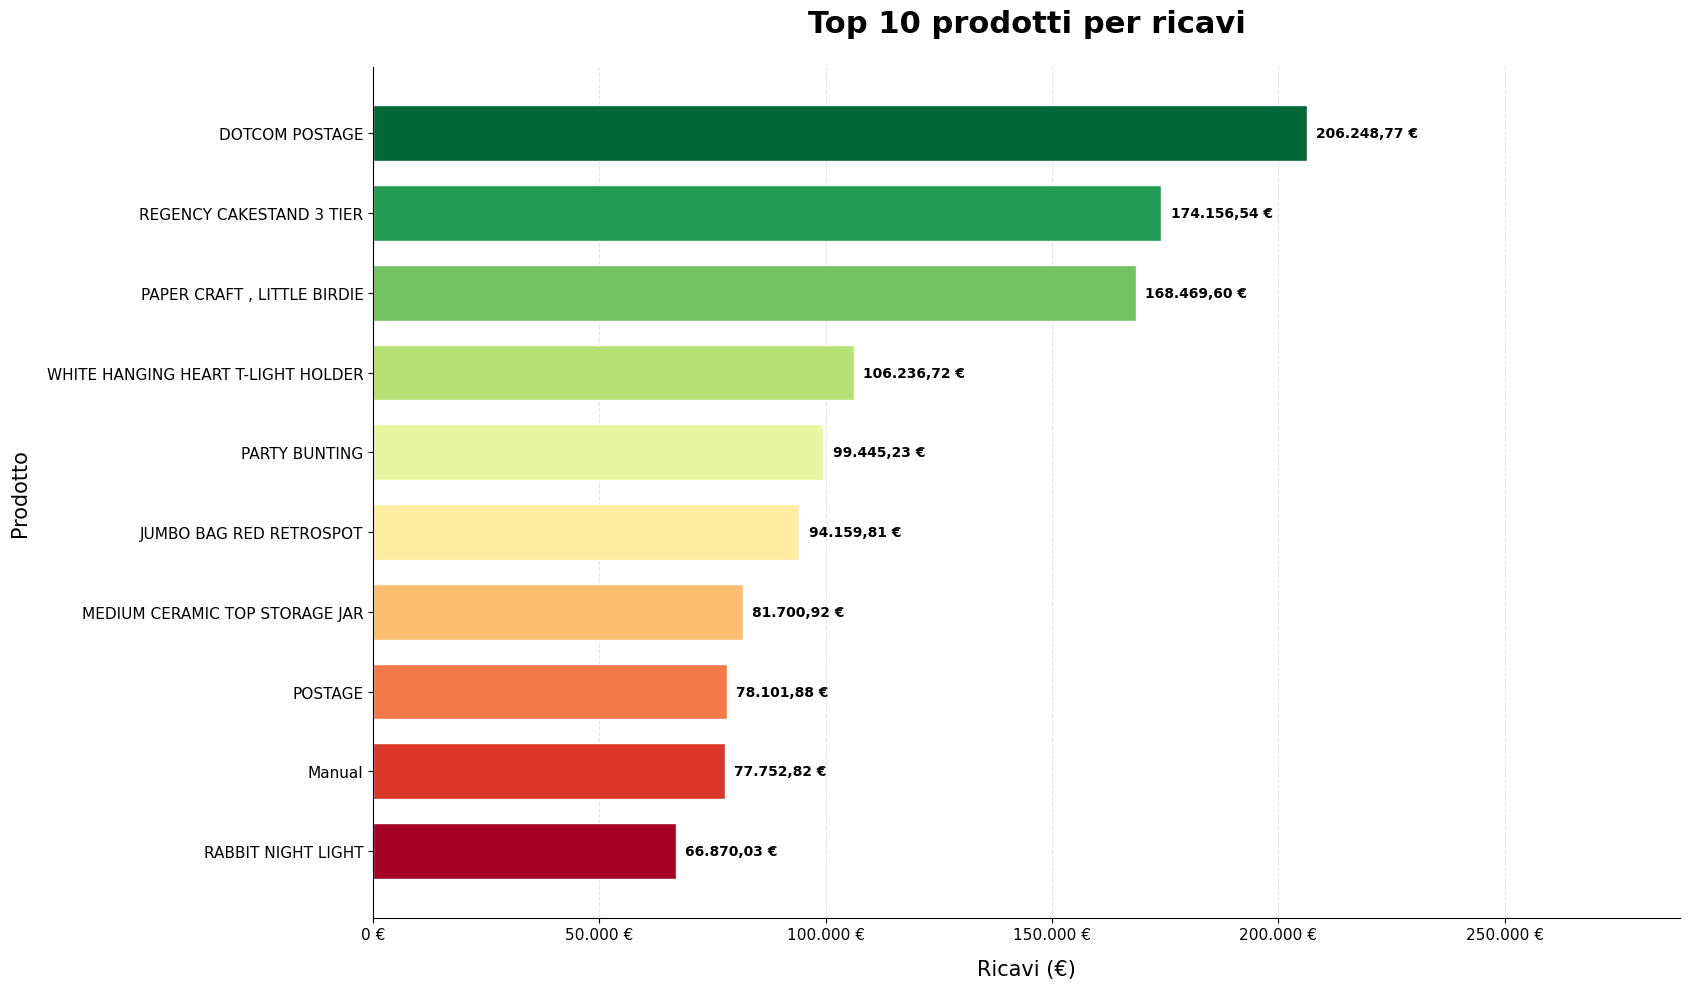

In [13]:
# Calcolo dei ricavi per prodotto
ricavi_prodotti = (
    df_pulito.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Selezione dei primi 10 prodotti
top_10_prodotti = ricavi_prodotti.head(10)

# Creazione di una tabella con i ricavi dei primi 10 prodotti
tabella_prodotti = pd.DataFrame({
    "Prodotto": top_10_prodotti.index,
    "Ricavi": top_10_prodotti.values
})

# Formattazione dei ricavi
tabella_prodotti["Ricavi"] = tabella_prodotti["Ricavi"].apply(formato_euro)

# Visualizzazione dei risultati
print("Top 10 prodotti per ricavi")
display(tabella_prodotti)

# Creazione del grafico
dati_grafico = top_10_prodotti.sort_values()

fig, ax = plt.subplots(figsize=(17, 10))

# Creazione della palette dal rosso al verde
colori = plt.cm.RdYlGn(
    [i / (len(dati_grafico) - 1) for i in range(len(dati_grafico))]
)

# Creazione delle barre orizzontali
barre = ax.barh(
    dati_grafico.index,
    dati_grafico.values,
    color=colori,
    edgecolor="white",
    height=0.7
)

# Impostazione del titolo e delle etichette
ax.set_title(
    "Top 10 prodotti per ricavi",
    fontsize=22,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Ricavi (€)", fontsize=15, labelpad=12)
ax.set_ylabel("Prodotto", fontsize=15, labelpad=12)

# Aumento della dimensione delle etichette
ax.tick_params(axis="both", labelsize=11)

# Formattazione dell'asse dei ricavi
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".") + " €"
    )
)

# Aggiunta della griglia
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Visualizzazione dei valori accanto alle barre
for barra in barre:
    valore = barra.get_width()

    ax.text(
        valore + max(dati_grafico.values) * 0.01,
        barra.get_y() + barra.get_height() / 2,
        formato_euro(valore),
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Impostazione dello spazio per le etichette
ax.set_xlim(0, max(dati_grafico.values) * 1.40)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    os.path.join(cartella, "top_10_prodotti.png"),
    dpi=300,
    bbox_inches="tight"
)

# Visualizzazione del grafico
plt.show()

## 6. Analisi temporale delle vendite

Analizziamo l'andamento dei ricavi nel tempo per individuare i mesi con le migliori performance commerciali.

Raggruppiamo le transazioni per mese e calcoliamo il totale dei ricavi generati in ciascun periodo.

Ricavi mensili


,Mese,Ricavi
0,2010-12,"821.452,73 €"
1,2011-01,"689.811,61 €"
2,2011-02,"522.545,56 €"
3,2011-03,"716.215,26 €"
4,2011-04,"536.968,49 €"
5,2011-05,"769.296,61 €"
6,2011-06,"760.547,01 €"
7,2011-07,"718.076,12 €"
8,2011-08,"757.841,38 €"
9,2011-09,"1.056.435,19 €"


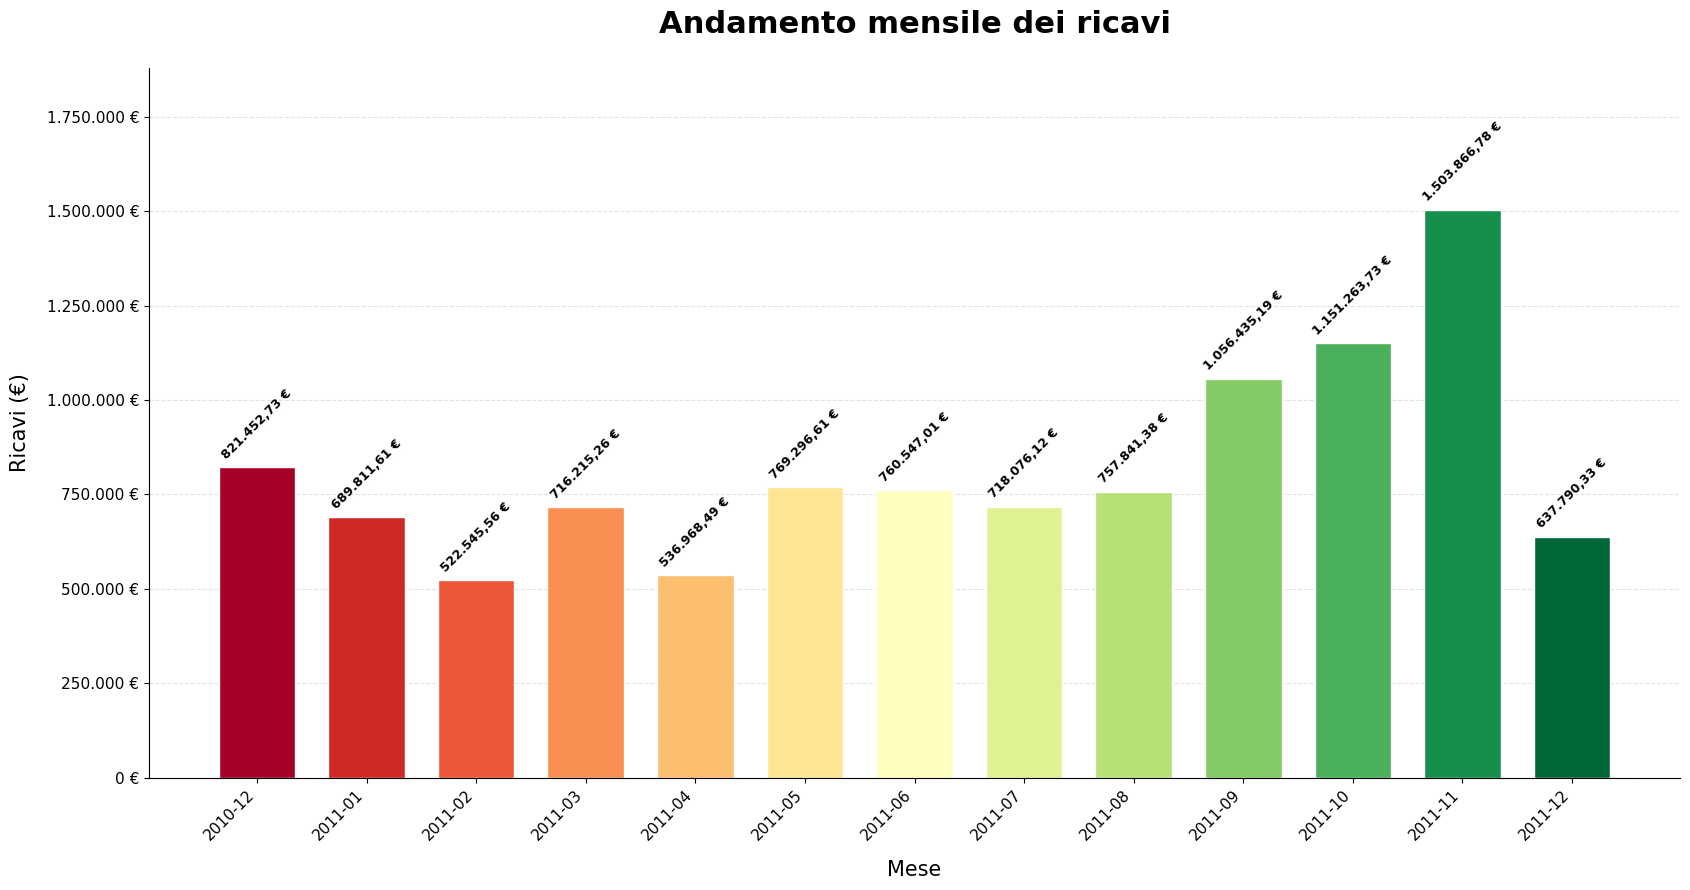

In [14]:
# Estrazione del mese e dell'anno dalla data della fattura
df_pulito["Mese"] = df_pulito["InvoiceDate"].dt.to_period("M")

# Calcolo dei ricavi mensili
ricavi_mensili = (
    df_pulito.groupby("Mese")["Revenue"]
    .sum()
    .sort_index()
)

# Creazione di una tabella con i ricavi mensili
tabella_mensile = pd.DataFrame({
    "Mese": ricavi_mensili.index.astype(str),
    "Ricavi": ricavi_mensili.values
})

# Formattazione dei ricavi
tabella_mensile["Ricavi"] = tabella_mensile["Ricavi"].apply(formato_euro)

# Visualizzazione dei risultati
print("Ricavi mensili")
display(tabella_mensile)

# Creazione del grafico
dati_grafico = ricavi_mensili

fig, ax = plt.subplots(figsize=(17, 9))

# Creazione della palette dal rosso al verde
colori = plt.cm.RdYlGn(
    [
        i / (len(dati_grafico) - 1)
        for i in range(len(dati_grafico))
    ]
)

# Creazione delle barre
barre = ax.bar(
    dati_grafico.index.astype(str),
    dati_grafico.values,
    color=colori,
    edgecolor="white",
    width=0.7
)

# Impostazione del titolo e delle etichette
ax.set_title(
    "Andamento mensile dei ricavi",
    fontsize=22,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Mese", fontsize=15, labelpad=12)
ax.set_ylabel("Ricavi (€)", fontsize=15, labelpad=12)

# Aumento della dimensione delle etichette
ax.tick_params(axis="both", labelsize=11)
plt.xticks(rotation=45, ha="right")

# Formattazione dell'asse dei ricavi
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".") + " €"
    )
)

# Aggiunta della griglia
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Visualizzazione dei valori sopra le barre
for barra in barre:
    valore = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valore + max(dati_grafico.values) * 0.01,
        formato_euro(valore),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        rotation=45
    )

# Impostazione dello spazio per le etichette
ax.set_ylim(0, max(dati_grafico.values) * 1.25)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    os.path.join(cartella, "andamento_mensile.png"),
    dpi=300,
    bbox_inches="tight"
)

# Visualizzazione del grafico
plt.show()

## 7. Segmentazione dei clienti con il modello RFM

Il modello RFM permette di segmentare i clienti in base al loro comportamento d'acquisto.

L'analisi considera tre indicatori:

- **Recency:** tempo trascorso dall'ultimo acquisto.
- **Frequency:** numero di ordini effettuati.
- **Monetary:** valore totale degli acquisti.

L'obiettivo è individuare i clienti più importanti, quelli più fedeli e quelli che potrebbero necessitare di strategie di recupero.

In [15]:
# Esclusione dei record senza identificativo cliente
df_clienti = df_pulito.dropna(subset=["CustomerID"]).copy()

# Definizione della data di riferimento per il calcolo della Recency
data_riferimento = df_clienti["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calcolo degli indicatori RFM per ciascun cliente
rfm = df_clienti.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (data_riferimento - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Visualizzazione delle prime righe della tabella RFM
display(rfm.head())

# Verifica del numero di clienti analizzati
print("Numero di clienti analizzati:", len(rfm))

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


Numero di clienti analizzati: 4338


### 7.1 Calcolo dei punteggi RFM

Assegniamo a ogni cliente un punteggio da 1 a 5 per ciascun indicatore.

Per la Recency il punteggio più alto viene assegnato ai clienti che hanno acquistato più recentemente.

Per Frequency e Monetary il punteggio più alto viene assegnato ai clienti con più ordini e maggiori ricavi generati.

I tre punteggi vengono combinati per ottenere il codice RFM complessivo.

In [16]:
# Calcolo dei punteggi Recency
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
)

# Calcolo dei punteggi Frequency
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Calcolo dei punteggi Monetary
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Creazione del punteggio RFM complessivo
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int).astype(str) +
    rfm["F_Score"].astype(int).astype(str) +
    rfm["M_Score"].astype(int).astype(str)
)

# Visualizzazione dei risultati
display(rfm.head())

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,115
12347.0,2,7,4310.00,5,5,5,555
12348.0,75,4,1797.24,2,4,4,244
12349.0,19,1,1757.55,4,1,4,414
12350.0,310,1,334.40,1,1,2,112


### 7.2 Identificazione dei segmenti di clientela

Utilizziamo i punteggi RFM per suddividere i clienti in quattro segmenti:

- **Migliori clienti:** clienti con punteggi elevati in tutte e tre le dimensioni.
- **Clienti fedeli:** clienti con elevata frequenza di acquisto.
- **Clienti da recuperare:** clienti che non acquistano da molto tempo.
- **Altri clienti:** clienti che non rientrano nei segmenti precedenti.

Questa classificazione permette di individuare gruppi di clienti su cui sviluppare strategie commerciali mirate.

In [17]:
# Funzione per assegnare un segmento a ciascun cliente
def segmenta_cliente(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Migliori clienti"
    elif row["F_Score"] >= 4:
        return "Clienti fedeli"
    elif row["R_Score"] <= 2:
        return "Clienti da recuperare"
    else:
        return "Altri clienti"

# Assegnazione dei segmenti
rfm["Segment"] = rfm.apply(segmenta_cliente, axis=1)

# Conteggio dei clienti per segmento
conteggio_segmenti = rfm["Segment"].value_counts()

# Visualizzazione dei risultati
print("Numero di clienti per segmento")
display(conteggio_segmenti.to_frame(name="Numero clienti"))

Numero di clienti per segmento


,Numero clienti
Segment,
Clienti da recuperare,1450
Altri clienti,1153
Migliori clienti,942
Clienti fedeli,793


### 7.3 Distribuzione dei clienti per segmento

Visualizziamo la distribuzione dei clienti nei quattro segmenti individuati attraverso il modello RFM.

Il grafico permette di confrontare il numero di clienti appartenenti a ciascun gruppo.

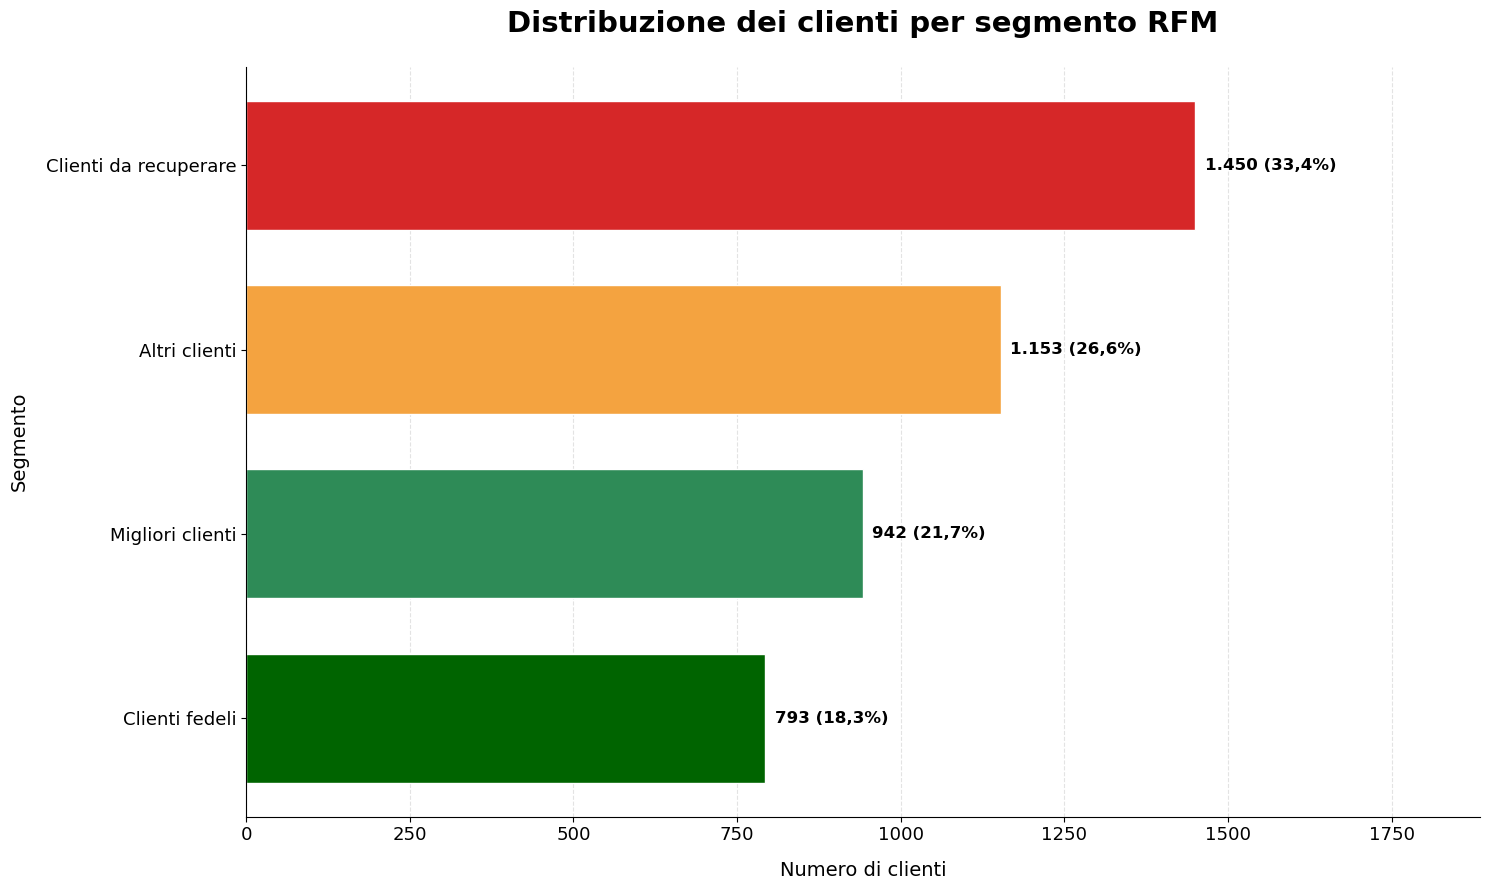

In [18]:
# Calcolo del numero di clienti per segmento
conteggio_segmenti = rfm["Segment"].value_counts()

# Ordinamento dei segmenti in base al numero di clienti
dati_grafico = conteggio_segmenti.sort_values()

# Definizione dei colori per ciascun segmento
colori_segmenti = {
    "Clienti fedeli": "#006400",
    "Migliori clienti": "#2E8B57",
    "Altri clienti": "#F4A340",
    "Clienti da recuperare": "#D62728"
}

# Assegnazione dei colori in base al segmento
colori = [colori_segmenti[segmento] for segmento in dati_grafico.index]

# Creazione del grafico
fig, ax = plt.subplots(figsize=(15, 9))

# Creazione delle barre orizzontali
barre = ax.barh(
    dati_grafico.index,
    dati_grafico.values,
    color=colori,
    edgecolor="white",
    height=0.7
)

# Impostazione del titolo e delle etichette
ax.set_title(
    "Distribuzione dei clienti per segmento RFM",
    fontsize=21,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Numero di clienti", fontsize=14, labelpad=12)
ax.set_ylabel("Segmento", fontsize=14, labelpad=12)

# Aumento della dimensione delle etichette
ax.tick_params(axis="both", labelsize=13)

# Aggiunta della griglia
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Visualizzazione dei valori e delle percentuali
for barra in barre:
    valore = int(barra.get_width())
    percentuale = valore / len(rfm) * 100

    ax.text(
        valore + max(dati_grafico.values) * 0.01,
        barra.get_y() + barra.get_height() / 2,
        f"{valore:,}".replace(",", ".") +
        f" ({percentuale:.1f}%)".replace(".", ","),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

# Impostazione dello spazio per le etichette
ax.set_xlim(0, max(dati_grafico.values) * 1.30)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    os.path.join(cartella, "segmentazione_clienti.png"),
    dpi=300,
    bbox_inches="tight"
)

# Visualizzazione del grafico
plt.show()

### 7.4 Analisi dei ricavi per segmento

Analizziamo il contributo economico dei diversi segmenti di clientela.

Colleghiamo le informazioni RFM alle transazioni originali per calcolare i ricavi complessivi generati da ciascun segmento.

Confrontiamo inoltre il numero di clienti e il ricavo medio per cliente.

In [19]:
# Associazione del segmento RFM a ogni transazione
df_segmenti = df_clienti.merge(
    rfm[["Segment"]],
    on="CustomerID",
    how="left"
)

# Calcolo dei ricavi e dei clienti per segmento
ricavi_segmenti = df_segmenti.groupby("Segment").agg(
    Numero_clienti=("CustomerID", "nunique"),
    Ricavi_totali=("Revenue", "sum")
)

# Calcolo del ricavo medio per cliente
ricavi_segmenti["Ricavo_medio_cliente"] = (
    ricavi_segmenti["Ricavi_totali"] /
    ricavi_segmenti["Numero_clienti"]
)

# Ordinamento dei segmenti per ricavi totali
ricavi_segmenti = ricavi_segmenti.sort_values(
    "Ricavi_totali",
    ascending=False
)

# Creazione di una copia formattata della tabella
tabella_ricavi_segmenti = ricavi_segmenti.copy()

# Formattazione degli importi
tabella_ricavi_segmenti["Ricavi_totali"] = (
    tabella_ricavi_segmenti["Ricavi_totali"].apply(formato_euro)
)

tabella_ricavi_segmenti["Ricavo_medio_cliente"] = (
    tabella_ricavi_segmenti["Ricavo_medio_cliente"].apply(formato_euro)
)

# Formattazione del numero di clienti
tabella_ricavi_segmenti["Numero_clienti"] = (
    tabella_ricavi_segmenti["Numero_clienti"].map(
        lambda x: f"{x:,}".replace(",", ".")
    )
)

# Visualizzazione dei risultati
print("Ricavi e clienti per segmento RFM")
display(tabella_ricavi_segmenti)

Ricavi e clienti per segmento RFM


,Numero_clienti,Ricavi_totali,Ricavo_medio_cliente
Segment,,,
Migliori clienti,942,"5.737.952,12 €","6.091,24 €"
Clienti fedeli,793,"1.380.979,45 €","1.741,46 €"
Clienti da recuperare,1.450,"894.360,02 €","616,80 €"
Altri clienti,1.153,"873.917,30 €","757,95 €"


### 7.5 Contributo dei segmenti ai ricavi

Visualizziamo i ricavi complessivi generati da ciascun segmento RFM.

Il grafico permette di individuare i gruppi di clienti che contribuiscono maggiormente al fatturato.

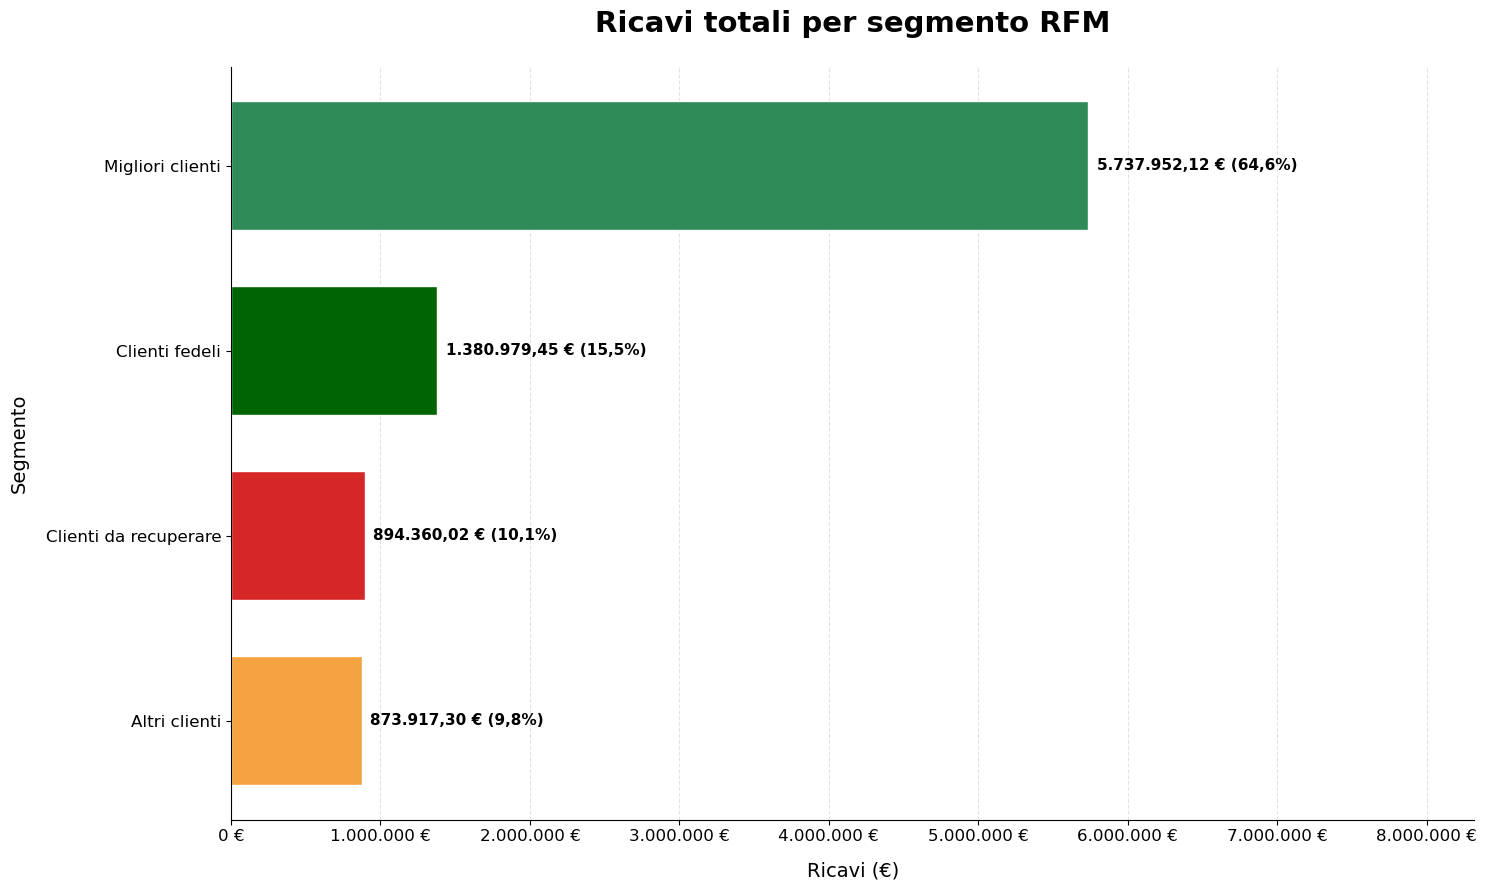

In [20]:
# Selezione dei ricavi per segmento
dati_grafico = ricavi_segmenti["Ricavi_totali"].sort_values()

# Calcolo della percentuale sul totale
percentuali = (
    dati_grafico / dati_grafico.sum() * 100
)

# Definizione dei colori per ciascun segmento
colori_segmenti = {
    "Clienti fedeli": "#006400",
    "Migliori clienti": "#2E8B57",
    "Altri clienti": "#F4A340",
    "Clienti da recuperare": "#D62728"
}

# Assegnazione dei colori in base al segmento
colori = [
    colori_segmenti[segmento]
    for segmento in dati_grafico.index
]

# Creazione del grafico
fig, ax = plt.subplots(figsize=(15, 9))

# Creazione delle barre orizzontali
barre = ax.barh(
    dati_grafico.index,
    dati_grafico.values,
    color=colori,
    edgecolor="white",
    height=0.7
)

# Impostazione del titolo e delle etichette
ax.set_title(
    "Ricavi totali per segmento RFM",
    fontsize=21,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Ricavi (€)", fontsize=14, labelpad=12)
ax.set_ylabel("Segmento", fontsize=14, labelpad=12)

# Aumento della dimensione delle etichette
ax.tick_params(axis="both", labelsize=12)

# Formattazione dell'asse dei ricavi
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".") + " €"
    )
)

# Aggiunta della griglia
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Visualizzazione dei ricavi e delle percentuali
for barra, percentuale in zip(
    barre,
    percentuali.loc[dati_grafico.index]
):
    valore = barra.get_width()

    ax.text(
        valore + max(dati_grafico.values) * 0.01,
        barra.get_y() + barra.get_height() / 2,
        formato_euro(valore) +
        f" ({percentuale:.1f}%)".replace(".", ","),
        va="center",
        fontsize=11,
        fontweight="bold"
    )

# Impostazione dello spazio per le etichette
ax.set_xlim(0, max(dati_grafico.values) * 1.45)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    os.path.join(cartella, "ricavi_segmenti.png"),
    dpi=300,
    bbox_inches="tight"
)

# Visualizzazione del grafico
plt.show()

### 7.6 Considerazioni sulla segmentazione RFM

L'analisi RFM permette di individuare differenze significative nel comportamento dei clienti.

I migliori clienti rappresentano il segmento con il maggiore contributo economico, mentre i clienti da recuperare costituiscono un gruppo su cui potrebbero essere sviluppate campagne di riattivazione.

I risultati possono supportare strategie di fidelizzazione, promozioni mirate e iniziative per aumentare il valore dei clienti nel tempo.

La segmentazione utilizzata si basa su soglie definite per questo progetto e non rappresenta una classificazione universale.

## 8. Esportazione dei dati

In questa sezione esportiamo i dataset elaborati durante l'analisi in formato CSV.

I file saranno utilizzati successivamente in Power BI per realizzare un dashboard interattivo.

Esporteremo:
- Il dataset delle vendite pulite.
- La tabella RFM con i segmenti dei clienti.

In [21]:
# Definizione della cartella principale del progetto
cartella_progetto = r"C:\Users\MSI\Desktop\Progetti\analisi-clienti"

# Esportazione del dataset delle vendite pulite
df_pulito.to_csv(
    os.path.join(cartella_progetto, "vendite_pulite.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Esportazione della tabella RFM con i segmenti dei clienti
rfm.to_csv(
    os.path.join(cartella_progetto, "clienti_rfm.csv"),
    index=True,
    encoding="utf-8-sig"
)

# Conferma del salvataggio dei file
print("Esportazione completata!")
print("File salvati nella cartella:", cartella_progetto)
print("- vendite_pulite.csv")
print("- clienti_rfm.csv")

Esportazione completata!
File salvati nella cartella: C:\Users\MSI\Desktop\Progetti\analisi-clienti
- vendite_pulite.csv
- clienti_rfm.csv


### 8.1 Verifica dei file esportati

Verifichiamo che i file CSV siano stati creati correttamente e siano disponibili per l'importazione in Power BI.

In [22]:
# Verifica dell'esistenza dei file esportati
file_esportati = [
    "vendite_pulite.csv",
    "clienti_rfm.csv"
]

for nome_file in file_esportati:
    percorso = os.path.join(cartella_progetto, nome_file)

    if os.path.exists(percorso):
        print(f"{nome_file}: file creato correttamente")
    else:
        print(f"{nome_file}: file non trovato")

vendite_pulite.csv: file creato correttamente
clienti_rfm.csv: file creato correttamente
